# Part 3 · M0：VTZ 基线

Matching 任务的层级扩散决策分析。M0 以条件性漂移率和非决策时间描述选择与反应时。

### 结果概要

42 名被试、19,580 个拟合试次；四链共 20,000 个保留样本。全部后验变量及目标对比达到 R-hat < 1.01、ESS-bulk / ESS-tail ≥ 400。

Match 条件的 Self 内 Good−Bad 漂移差为 0.948，95% HDI [0.835, 1.067]；Mismatch 对比为 -0.006 [-0.119, 0.099]。

四链 DIC：M0 = -3552.29，M1 = -3602.35，差值 50.06，相对比较偏向 M1。每模型完成 2,000 次 PPC；八条件 RT 第 90 百分位平均高估约 0.150 秒。

结果日期：2026-11-11。[完整诊断](../../Output/tables/M0_20261111_diagnostics.csv) · [参数概要](../../Output/tables/M0_20261111_posterior_summary.csv) · [运行来源](../../Output/tables/M0_20261111_provenance.json)


## 1. Model Specification

### 环境与数据

HDDM 1.0.1RC / ArviZ 0.15.1；运行环境为 `hu2020-part3:pyddm090-tail`。以下结果基于已保存的四链后验，采样、DIC 和 PPC 分别计算。

In [1]:
# 定位项目目录，导入共享函数并记录运行环境。
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", message="The 'float_precision'.*deprecated.*")
# 忽略锁定版 ArviZ 的绘图弃用提示。
warnings.filterwarnings("ignore", message="The return type of `Dataset.dims`", category=FutureWarning, module="arviz.*")

PROJECT = next((p for parent in (Path.cwd(), *Path.cwd().parents)
                for p in (parent, parent / "03_alternative_mechanisms")
                if p.name == "03_alternative_mechanisms" and (p / "Scripts/common").is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError("请从本仓库或本项目目录内打开 Notebook。")
sys.path.insert(0, str(PROJECT / "Scripts"))
from common.data_utils import load_data, dataset_hash
MODEL = "M0"
SEED = 2026110719
np.random.seed(SEED)
DATA = PROJECT / "Data/processed"
OUT = PROJECT / "Output/tables"
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11})
from importlib.metadata import version, PackageNotFoundError
import platform
versions = {"Python": platform.python_version()}
for package in ("numpy", "pandas", "arviz", "hddm", "kabuki"):
    try: versions[package] = version(package)
    except PackageNotFoundError: versions[package] = "not installed"
display(pd.Series(versions, name="runtime"))

Python      3.9.13
numpy       1.23.3
pandas       2.0.1
arviz       0.15.1
hddm      1.0.1rc0
kabuki    0.6.5rc4
Name: runtime, dtype: object

In [2]:
# 计算阶段、随机种子与采样预算。
RUN_FIT = False
RUN_DIC = False
RUN_PPC = False
RUN_PRIOR = False
RUN_PPC_DENSITY = False  # 重放分布图所需的预测数据。
RUN_POSTPROCESS = False  # 保存诊断和参数汇总。
N_CHAINS = 4
N_SAMPLES = 10000       # 每链总迭代，包含 burn-in。
N_BURN = 5000
N_WORKERS = 1          # 本 Notebook 的并发链数。
N_PRIOR = 2000
RUN_ID = "chain_comparison_20261109"
MODEL_ROOTS = {name: PROJECT/"Output"/directory/"local_bulk"/RUN_ID
    for name, directory in {"M0": "tables", "M1": "01_starting_point_z"}.items()}
FIT_ROOT = MODEL_ROOTS[MODEL]
assert 1 <= N_WORKERS <= 16 and N_CHAINS >= 1
N_PPC_PER_CHAIN = 500
N_PPC_DENSITY = 100     # 分布图使用已有 PPC 抽样记录的前 100 组。
NUMERICS = None
LIMITATIONS = "RT 下限选择及 Deadline 尚未建模。"
print(f"{MODEL}: 目标 {N_CHAINS} 链，每链 {N_SAMPLES} 次，burn-in {N_BURN}；seed={SEED}。")
print("观察模型限制：", LIMITATIONS)

REPORT_DATE = "20261111"


M0: 目标 4 链，每链 10000 次，burn-in 5000；seed=2026110719。
观察模型限制： RT 下限选择及 Deadline 尚未建模。


### 分析样本

保留 42 名被试的合法反应，RT ≥ 0.2 秒，包含正确及错误反应，不另设 RT 上限。24,499 个有效试次中，固定划分的 19,580 个用于拟合、DIC 和 PPC；另外 4,919 个未用于本分析。

八条件为 Match/Mismatch × Good/Bad × Self/Other。上边界代表 Match 选择（response=1），下边界代表 Mismatch 选择（response=0）；stim=1/0 分别表示 Match/Mismatch 刺激。正确率为 response 与 stim 相同的比例。下表描述全部有效试次。

In [3]:
# 读取试次并核验 RT、反应编码和数据版本。
data = load_data()
train = pd.read_csv(DATA / "matching_rt_ge_0p2_train.csv.gz", float_precision="round_trip")
split = json.loads((DATA / "rt_ge_0p2_split_manifest.json").read_text())
assert len(data) == 24499 and data.subj_idx.nunique() == 42
assert data.rt.ge(.2).all() and set(data.response.unique()) == {0, 1}
assert ((data.response == data.stim).astype(int) == data.accuracy).all()
assert data.groupby(["subj_idx", "match", "val", "id"]).ngroups == 42 * 8
# 拟合、DIC 与 PPC 使用同一试次集合。
assert set(train.event_id).issubset(set(data.event_id))
assert dataset_hash(train) == split["train_hash"]
assert len(train) == 19580
display(data.groupby(["match", "val", "id"]).agg(
    trials=("rt", "size"), participants=("subj_idx", "nunique"),
    rt_min_s=("rt", "min"), rt_max_s=("rt", "max")))
print(f"有效数据 {len(data):,} 条；当前链拟合及 DIC/PPC 使用 {len(train):,} 条。")

trials  participants  rt_min_s  rt_max_s
match    val  id                                             
match    Bad  Other    3062            42    0.2633    1.1344
              Self     3062            42    0.2075    1.1374
         Good Other    3077            42    0.2155    1.1514
              Self     3104            42    0.2040    1.1078
mismatch Bad  Other    3049            42    0.2413    1.1216
              Self     3048            42    0.2550    1.0965
         Good Other    3028            42    0.2219    1.1685
              Self     3069            42    0.2396    1.1503

有效数据 24,499 条；当前链拟合及 DIC/PPC 使用 19,580 条。


### 基线与共同先验

$$M_0:\quad \mu_{i,c}=s_c v_{i,c},\quad t_{0,i,c},\quad a_i,\quad z_i.$$

$c$ 表示八种条件；$s_c=+1$ 对应 Match，$-1$ 对应 Mismatch。$v,t_0$ 随条件变化，$a,z$ 在被试内共享，不含独立 $dc$。

$v\in\mathbb R$，$a,t_0>0$，$0<z<1$。边界为 $0,a$，初始点为 $az$，扩散尺度为 1，$p_{outlier}=0$；决策时间为 $\tau=RT-t_0$。

| 参数 | 群体位置先验 | 个体分布与被试间标准差 |
|---|---|---|
| 八条件 $v$ | $N(2,3^2)$ | Normal；共享 SD $\sim\mathrm{HalfNormal}(2)$ |
| 八条件 $t_0$ | Gamma(shape=4, rate=10) | 按均值/SD 参数化的 Gamma；共享 SD $\sim\mathrm{HalfNormal}(1)$ |
| $a$ | Gamma(shape=4, rate=8/3) | 按均值/SD 参数化的 Gamma；SD $\sim\mathrm{HalfNormal}(2)$ |
| $\mathrm{logit}(z)$ | $N(0,0.5^2)$ | Normal；SD $\sim\mathrm{HalfNormal}(0.05)$ |

先验采用 HDDM 1.0.1RC 的原生实现；表中共享 SD 指八个条件共用同一个被试间标准差。正的 $v$ 指向该刺激的正确边界；Mismatch 条件的总漂移为 $-v$。

[实际先验节点](../../Output/tables/comparison_actual_prior_nodes.json) · [模型实现](../common/baseline_v.py)

### 实现核验

采用 HDDM 原生 Wiener 首达时间似然。模型构建、初始化及生成器检查见[验证记录](../../Output/tables/M0_M1_validation_20261111.md)；实证后验诊断见第 3 章。

### 参数先验

联合参数先验抽样设为 2,000 次，尚未执行。该步骤生成参数样本，不生成行为预测。

In [4]:
# 抽取并保存联合参数先验；此处不生成行为数据。
if RUN_PRIOR:
    import arviz as az
    from common.simulation_utils import prior_parameters
    for name in ("M0",):
        path = FIT_ROOT / (name + "_prior.nc")
        if path.exists(): raise FileExistsError("先验文件已存在：" + str(path))
        values = prior_parameters(train, name, draws=N_PRIOR, seed=SEED, dynamic=NUMERICS, noncentered=(name == "M1"))
        prior = az.from_dict(prior={k: values[k].to_numpy()[None, :] for k in values})
        prior.attrs.update(model_id=name, data_hash=dataset_hash(train), n_prior=N_PRIOR)
        path.parent.mkdir(parents=True, exist_ok=True)
        prior.to_netcdf(path)
        display(values.describe().T)

## 2. Model Fitting

四条独立链，每链 10,000 次迭代、burn-in 5,000、thinning 1，共保留 20,000 个样本。模型调用 HDDM 原生采样器；链配置和后验分别保存。

In [5]:
# 按既定预算运行本模型，复用已完成链。
from common.evaluation_utils import fit_models
if RUN_FIT:
    display(pd.DataFrame(fit_models(train, FIT_ROOT, models=(MODEL,), chains=N_CHAINS,
        samples=N_SAMPLES, burn=N_BURN, thin=1, workers=N_WORKERS,
        seed=SEED, max_models=1, dynamic=NUMERICS,
        noncentered=True if MODEL == "M1" else None,
        production=True, incremental=True, allow_sampling=True)))

### 后验读取

完整链按数据、模型、先验和实现版本核对后合并。

In [6]:
# 核验配置并读取已完成链。
from common.baseline_v import DEFAULT_PRIORS, cell_key
from common.evaluation_utils import inference_data, posterior_stamp, code_fingerprint
posteriors = {}; stamps = {}
path = FIT_ROOT/MODEL
if list(path.glob("chain_*/complete.json")):
    posterior, configs = inference_data(path)
    cfg = configs[0]
    assert cfg["data_hash"] == dataset_hash(train) and cfg["model"] == MODEL
    assert cfg["priors"] == DEFAULT_PRIORS and cfg.get("dynamic") == NUMERICS
    assert cfg["samples"] == N_SAMPLES and cfg["burn"] == N_BURN and cfg["seed_base"] == SEED
    assert cfg["chain_layout"] == "incremental-v1"
    current_code = code_fingerprint()
    # 兼容已核验的原生 M0/M1 版本；这两个指纹的差异仅涉及动态求解器。
    if (cfg["code"].get("common/baseline_v.py") == "e98c5615a049e8ca95990ead08432c70cc83fa52cb00cc9a7036858afe4ebe60"
            and current_code.get("common/baseline_v.py") == "cf3ac33e66799009601738e4f53c8ee69cbdcde634287660c2a8a1a15894463f"):
        current_code["common/baseline_v.py"] = cfg["code"]["common/baseline_v.py"]
    assert cfg["code"] == current_code, "代码已变更，请保留旧运行并使用新的 RUN_ID。"
    if MODEL == "M1": assert cfg.get("starting_effect_parameterization") == "noncentered"
    posteriors[MODEL] = posterior
    stamps[MODEL] = posterior_stamp(path)
    print(MODEL, "已完成链数:", len(configs), "；目标链数:", N_CHAINS)
else:
    print(MODEL, "缺少完整链后验。")

M0 已完成链数: 4 ；目标链数: 4


## 3. Model Diagnosis

全部 828 项后验变量（含参数变换及派生对比）通过采样诊断：最大 R-hat = 1.00138，最小 ESS-bulk = 3939，最小 ESS-tail = 6724。MCSE 保留在诊断表中。

表格列出 R-hat 最高的 12 项。R-hat 衡量链间一致性，ESS-bulk / ESS-tail 为分布主体与尾部的有效样本量，MCSE 为 Monte Carlo 标准误。图中依次展示四链轨迹、自相关和合并后验的 95% 最高密度区间（HDI）。

目标漂移对比为 $\Delta v_{\mathrm{Match}}$ 与 $\Delta v_{\mathrm{Mismatch}}$：分别计算每名被试 Self 内 Good−Bad 差异，再对 42 名被试等权平均。

图中的 $\mu_a$ 为群体边界均值，$\sigma_v,\sigma_{t_0}$ 为被试间标准差，$\mu_{\mathrm{logit}(z)}$ 为 logit 起点的群体均值。

In [7]:
# 在同一 chain/draw 内计算条件对比，保留参数间相关性。
subjects = sorted(train.subj_idx.unique())
for name, trace in posteriors.items():
    p = trace.posterior
    for direction in ("match", "mismatch"):
        differences = [p[cell_key("v", "Self", direction, "Good", s)] -
                       p[cell_key("v", "Self", direction, "Bad", s)] for s in subjects]
        p["delta_v_" + direction] = sum(differences) / len(subjects)
        for label, left, right in (
            ("GoodSelf_GoodOther", ("Self", "Good"), ("Other", "Good")),
            ("GoodOther_BadOther", ("Other", "Good"), ("Other", "Bad")),
            ("BadSelf_BadOther", ("Self", "Bad"), ("Other", "Bad"))):
            p["delta_v_" + direction + "_" + label] = sum(
                p[cell_key("v", left[0], direction, left[1], subject)] -
                p[cell_key("v", right[0], direction, right[1], subject)]
                for subject in subjects) / len(subjects)

In [8]:
# 诊断后验变量及派生对比，列出 R-hat 最高和未达标的项。
diagnostics = {}; diagnostic_pass = {}
if posteriors:
    import arviz as az
for name, trace in posteriors.items():
    table = az.summary(trace, kind="all", hdi_prob=.95, round_to="none")
    if trace.posterior.sizes["chain"] == 1:
        table["r_hat"] = np.nan
        print(name, "单链：R-hat 不适用；ESS/MCSE 仅用于探索。")
    table["passed"] = (np.isfinite(table[["r_hat", "ess_bulk", "ess_tail"]]).all(axis=1) &
                       table.r_hat.lt(1.01) & table.ess_bulk.ge(400) & table.ess_tail.ge(400))
    diagnostic_pass[name] = bool(trace.posterior.sizes["chain"] >= 4 and table.passed.all())
    if hasattr(trace, "sample_stats") and "diverging" in trace.sample_stats:
        divergences = int(trace.sample_stats.diverging.sum())
        diagnostic_pass[name] &= divergences == 0
        print(name, "NUTS divergences:", divergences)
    diagnostics[name] = table
    display(table.sort_values("r_hat", ascending=False).head(12)
        [["r_hat", "ess_bulk", "ess_tail", "mcse_mean", "mcse_sd"]]
        .rename(columns={"r_hat": "R-hat", "ess_bulk": "ESS-bulk", "ess_tail": "ESS-tail",
                         "mcse_mean": "MCSE mean", "mcse_sd": "MCSE SD"})
        .style.format({"R-hat": "{:.4f}", "ESS-bulk": "{:.0f}", "ESS-tail": "{:.0f}",
                       "MCSE mean": "{:.5f}", "MCSE SD": "{:.5f}"}))
    if trace.posterior.sizes["chain"] >= 2 and not table.passed.all():
        display(table.loc[~table.passed])
    elif trace.posterior.sizes["chain"] == 1:
        display(table.loc[table.ess_bulk.lt(400) | table.ess_tail.lt(400)].head(12))
    print(name, "全参数及目标诊断通过:", diagnostic_pass[name])
    if RUN_POSTPROCESS: table.to_csv(FIT_ROOT / (name + "_diagnostics.csv"))
    if RUN_POSTPROCESS:
        trace.to_netcdf(FIT_ROOT/name / "posterior.nc")
if not posteriors:
    print("诊断待完成：缺少当前后验。")

,R-hat,ESS-bulk,ESS-tail,MCSE mean,MCSE SD
a_subj.7338,1.0014,6970,9874,0.00053,0.00037
a_subj.7345,1.0010,8362,10179,0.00037,0.00026
t_subj(Self.match.Good).7326,1.0009,14761,13196,0.00005,0.00004
t_subj(Self.match.Bad).7327,1.0009,14122,12741,0.00008,0.00006
z_subj_trans.7320,1.0009,8076,11444,0.00066,0.00047
z_subj.7320,1.0009,8076,11444,0.00016,0.00012
t_subj(Other.mismatch.Good).7305,1.0009,10426,12392,0.00013,0.00009
a_subj.7326,1.0009,7970,11608,0.00040,0.00029
z_subj.7318,1.0008,8399,11162,0.00016,0.00011
z_subj_trans.7318,1.0008,8399,11162,0.00065,0.00046


M0 全参数及目标诊断通过: True


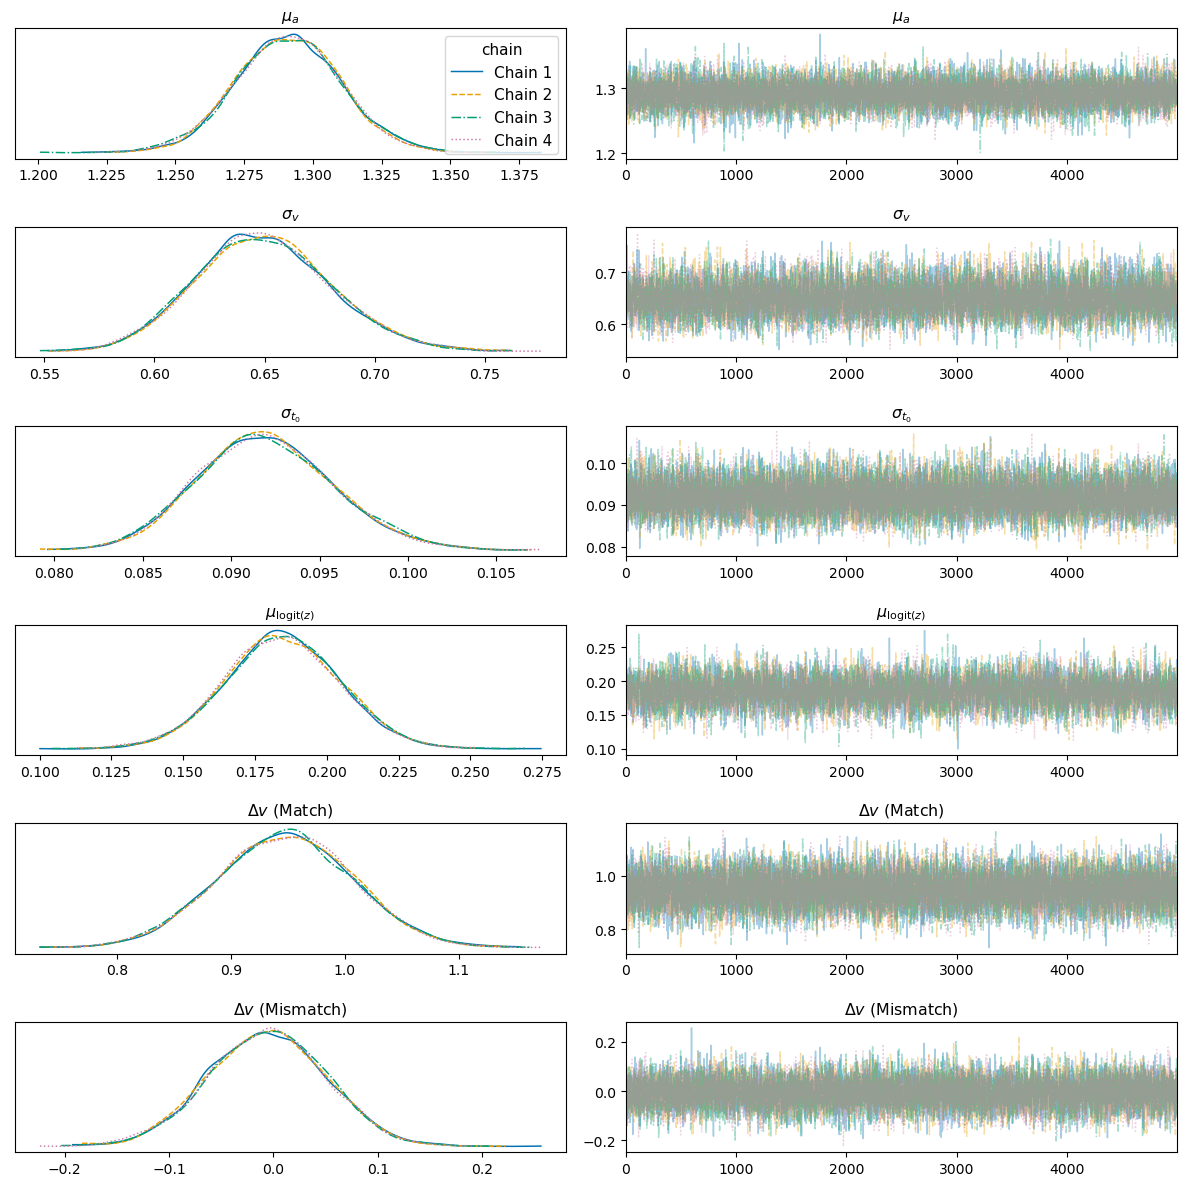

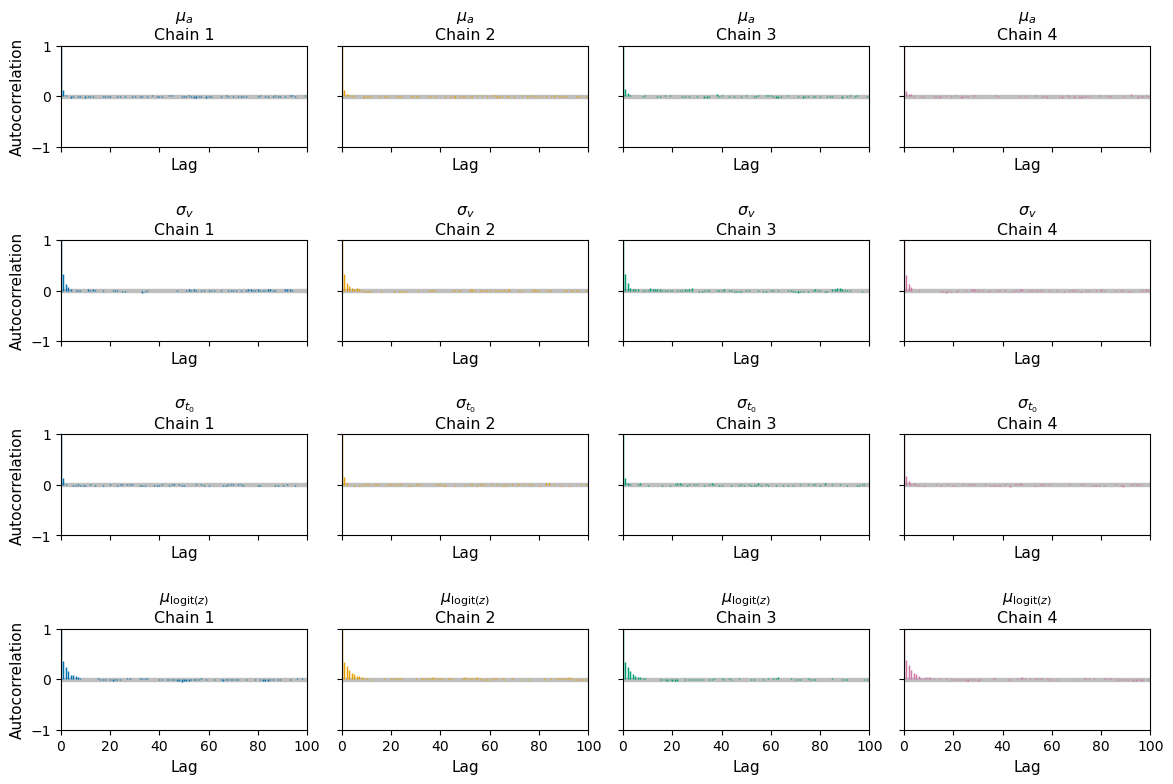

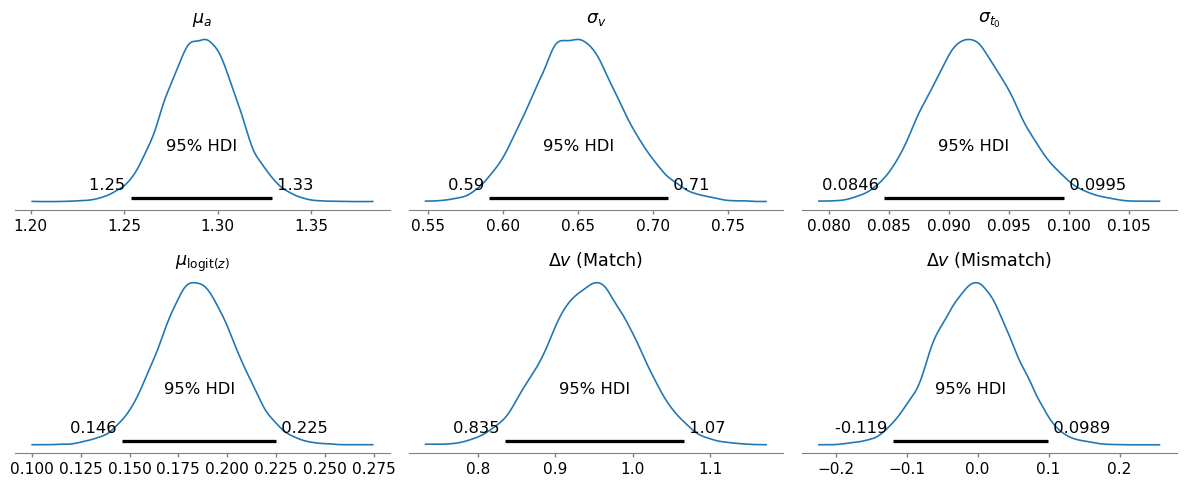

In [9]:
# 查看关键参数的链轨迹、自相关及后验分布。
parameter_labels = {
    "a": r"$\mu_a$", "v_std": r"$\sigma_v$",
    "t_std": r"$\sigma_{t_0}$", "z_trans": r"$\mu_{\mathrm{logit}(z)}$",
    "delta_v_match": r"$\Delta v$ (Match)",
    "delta_v_mismatch": r"$\Delta v$ (Mismatch)",
}
for name, trace in posteriors.items():
    key_names = [v for v in trace.posterior.data_vars
                 if v in ('a', 'v_std', 't_std', 'z_trans', 'delta_v_match', 'delta_v_mismatch')]
    if not key_names: key_names = list(trace.posterior.data_vars)[:4]
    colors = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
    chain_labels = {value: f"Chain {i+1}" for i, value in enumerate(trace.posterior.chain.values)}
    labeller = az.labels.MapLabeller(var_name_map=parameter_labels, coord_map={"chain": chain_labels})
    # 颜色和线型区分四条链，保留原始参数名用于结果读取。
    axes = az.plot_trace(trace, var_names=key_names, compact=False, combined=False,
        chain_prop={"color": colors, "linestyle": ["-", "--", "-.", ":"]},
        labeller=labeller, legend=True, figsize=(12, 2*len(key_names)))
    for axis in axes.flat:
        legend = axis.get_legend()
        if legend is not None:
            for number, label in enumerate(legend.get_texts(), start=1):
                label.set_text(f"Chain {number}")
    plt.tight_layout(h_pad=1.5)
    if RUN_POSTPROCESS: plt.savefig(FIT_ROOT/(name+"_trace.png"), dpi=150, bbox_inches="tight")
    plt.show()
    # 每行一个参数、每列一条链，保留默认的前 100 个滞后。
    n_chains = trace.posterior.sizes["chain"]
    axes = az.plot_autocorr(trace, var_names=key_names[:4], combined=False,
        grid=(min(4, len(key_names)), n_chains), figsize=(3*n_chains, 8),
        textsize=10, labeller=labeller)
    for i, axis in enumerate(np.asarray(axes).flat):
        axis.set_xlabel("Lag")
        if i % n_chains == 0: axis.set_ylabel("Autocorrelation")
        for artist in axis.collections[1:]: artist.set_color(colors[(i % n_chains) % len(colors)])
    plt.tight_layout(h_pad=1.8)
    if RUN_POSTPROCESS: plt.savefig(FIT_ROOT/(name+"_autocorrelation.png"), dpi=150, bbox_inches="tight")
    plt.show()
    az.plot_posterior(trace, var_names=key_names, hdi_prob=.95, point_estimate=None,
        round_to=3, labeller=labeller, grid=(2, 3), figsize=(12, 5), textsize=11)
    plt.tight_layout()
    if RUN_POSTPROCESS: plt.savefig(FIT_ROOT/(name+"_posterior.png"), dpi=150, bbox_inches="tight")
    plt.show()

### 八条件群体参数轨迹

分别展示条件性 $v$ 与 $t_0$ 的群体均值。左列为各链后验密度，右列为保留样本轨迹；四链颜色与前图一致。

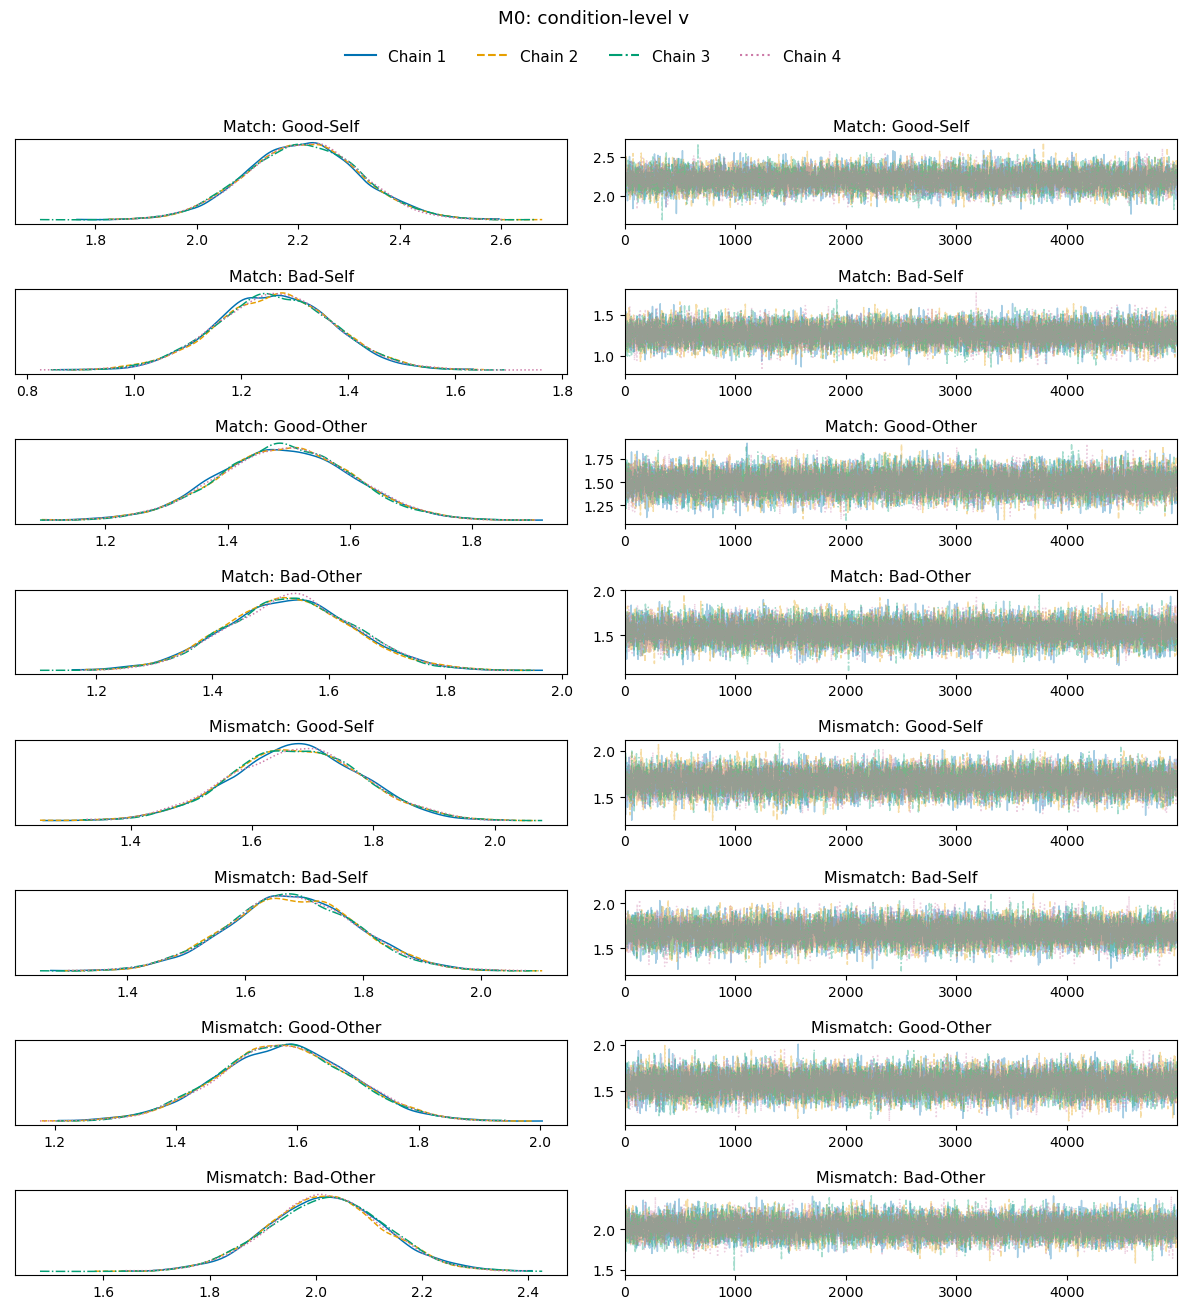

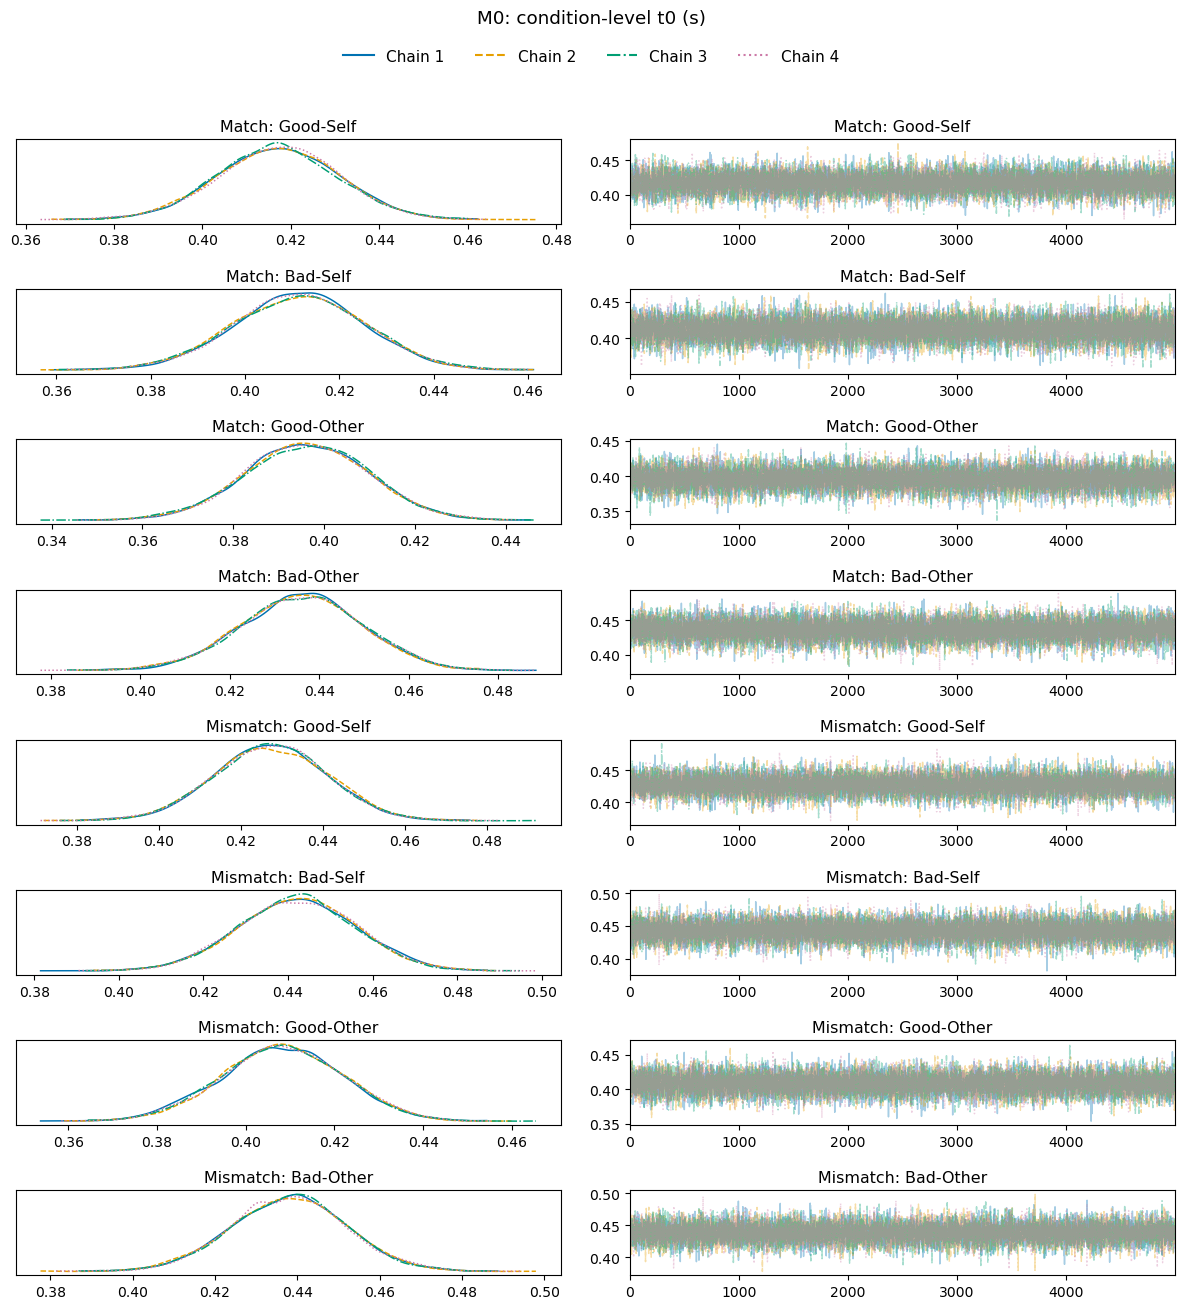

In [10]:
# 按条件检查 v、t0 群体均值的四链轨迹；颜色与前图一致。
condition_order = [(match, identity, val) for match in ("match", "mismatch")
                   for identity in ("Self", "Other") for val in ("Good", "Bad")]
condition_labels = [f"{match.title()}: {val}-{identity}"
                    for match, identity, val in condition_order]
if MODEL in posteriors:
    for parameter, symbol in (("v", "v"), ("t", "t0 (s)")):
        names = [f"{parameter}({identity}.{match}.{val})"
                 for match, identity, val in condition_order]
        labeller = az.labels.MapLabeller(var_name_map=dict(zip(names, condition_labels)))
        axes = az.plot_trace(posteriors[MODEL], var_names=names, compact=False,
            combined=False, chain_prop={"color": colors, "linestyle": ["-", "--", "-.", ":"]},
            labeller=labeller, legend=False, figsize=(12, 13))
        from matplotlib.lines import Line2D
        handles = [Line2D([], [], color=colors[i], linestyle=style, label=f"Chain {i+1}")
                   for i, style in enumerate(["-", "--", "-.", ":"])]
        figure = axes[0, 0].figure
        figure.suptitle(f"{MODEL}: condition-level {symbol}", y=1.005)
        figure.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, .985), ncol=4, frameon=False)
        plt.tight_layout(h_pad=1.4, rect=(0, 0, 1, .96))
        plt.show()


## 4. Model Comparison & PPC

### DIC

采用 HDDM 原生 DIC，使用四链合并样本：

$$D(\theta)=-2\log p(y\mid\theta),\qquad p_D=\overline D-D(\overline\theta),\qquad DIC=\overline D+p_D.$$

M0 与 M1 使用相同的 19,580 个试次和共同参数先验。DIC 越小表示拟合与复杂度的权衡越有利；它依赖参数化，差值不等同于显著性检验或 Bayes factor。

四链 DIC 差值为 **50.06**，偏向 M1。

[模型比较表](../../Output/tables/M0_M1_20261111_dic.csv)

In [11]:
# 读取已保存的原生模型；合并完整链后调用 HDDM/PyMC 的 DIC。
if RUN_DIC and MODEL in posteriors:
    import hddm, kabuki
    chain_paths = sorted((FIT_ROOT/MODEL).glob("chain_*/complete.json"))
    fitted = [hddm.load(str(p.parent/"model.hddm")) for p in chain_paths]
    # 不平均各链 DIC：用合并参数样本和合并 deviance 样本计算一次。
    combined = fitted[0] if len(fitted) == 1 else kabuki.utils.concat_models(fitted)
    if len(fitted) > 1:
        combined.mc.db.trace("deviance")._trace[0] = np.concatenate(
            [m.mc.db.trace("deviance")() for m in fitted])
    info = combined.dic_info
    stamp = stamps[MODEL]
    row = dict(model=MODEL, n_chains=stamp["n_chains"],
        n_draws=sum(len(m.mc.db.trace("deviance")()) for m in fitted),
        DIC=float(info["DIC"]), mean_deviance=float(info["deviance"]), pD=float(info["pD"]),
        data_hash=dataset_hash(train), n_events=len(train), posterior_hash=stamp["posterior_hash"],
        method="DIC_pD_stochastic_mean", comparison_group="HDDM_common_priors",
        diagnostics_pass=diagnostic_pass.get(MODEL, False))
    # 非有限结果如实保留，不删除观测、后验样本或填补似然。
    row["status"] = "computed" if np.isfinite([row["DIC"], row["pD"]]).all() else "undefined"
    pd.DataFrame([row]).to_csv(FIT_ROOT/MODEL/("dic_"+stamp["posterior_hash"][:16]+".csv"), index=False)
    display(pd.DataFrame([row])[["model", "n_chains", "DIC", "mean_deviance", "pD", "status"]])
    del fitted, combined
elif RUN_DIC:
    print("DIC 待完成：本模型尚无完整链。")


In [12]:
# 按后验指纹读取 DIC，并在相同比较组内计算差值。
from common.evaluation_utils import posterior_stamp
records = []
for name, root in MODEL_ROOTS.items():
    directory = root/name
    if not list(directory.glob("chain_*/complete.json")):
        records.append(dict(model=name, status="no_complete_chain"))
        continue
    stamp = posterior_stamp(directory, allow_incomplete=True)
    path = directory/("dic_"+stamp["posterior_hash"][:16]+".csv")
    if not path.exists():
        records.append(dict(model=name, n_chains=stamp["n_chains"], status="DIC_not_computed"))
        continue
    row = pd.read_csv(path, float_precision="round_trip").iloc[0].to_dict()
    assert row["model"] == name and row["posterior_hash"] == stamp["posterior_hash"]
    assert row["data_hash"] == dataset_hash(train) and int(row["n_events"]) == len(train)
    records.append(row)
comparison = pd.DataFrame(records)
comparison["delta_DIC"] = np.nan
if "DIC" in comparison:
    # 不同共同先验或似然实现的结果分别归组。
    for group, part in comparison.groupby("comparison_group"):
        valid = part.index[np.isfinite(part.DIC)]
        if len(valid) >= 2:
            comparison.loc[valid, "delta_DIC"] = comparison.loc[valid, "DIC"] - comparison.loc[valid, "DIC"].min()
display(comparison.reindex(columns=["model", "n_chains", "DIC", "delta_DIC", "mean_deviance", "pD"])
    .rename(columns={"model": "Model", "n_chains": "Chains", "delta_DIC": "Delta DIC",
                     "mean_deviance": "Mean deviance"})
    .style.hide(axis="index").format({"DIC": "{:.2f}", "Delta DIC": "{:.2f}",
                                     "Mean deviance": "{:.2f}", "pD": "{:.2f}"}, na_rep="—"))
print("DIC：同一组 19,580 个拟合试次；数值越小越有利。")

if RUN_DIC:
    comparison.to_csv(MODEL_ROOTS["M0"] / "dic_comparison.csv", index=False)


Model,Chains,DIC,Delta DIC,Mean deviance,pD
M0,4,-3552.29,50.06,-4207.56,655.28
M1,4,-3602.35,0.00,-4275.69,673.34


DIC：同一组 19,580 个拟合试次；数值越小越有利。


### 后验预测检验

从四链后验等概率抽取链和保留样本，生成 2,000 个完整复制数据集；总量按 500×链数设定。每个复制保留观测设计与各条件试次数。图中为各统计量的预测均值及 2.5%–97.5% 预测区间，黑色标记为观测值。

检查上边界选择比例、正确率、正确／错误 RT 和 RT 分位数。预测为未截断分布；观测数据的 RT 下限选择及 Deadline 过程未进入似然。

汇总表对八个条件等权平均；RT 分位数的平均值不是合并全部试次后的分位数。误差为预测均值减观测值，MSE 为八条件误差的均方，`outside_95` 为观测值落在预测区间外的条件数。

[分条件 PPC](../../Output/tables/M0_20261111_ppc_summary.csv)

In [13]:
# 后验指纹区分不同链集合的 PPC。
from common.evaluation_utils import posterior_predictive
ppc_tables = {}
for name in posteriors:
    stamp = stamps[name]
    count = stamp["n_chains"] * N_PPC_PER_CHAIN
    directory = FIT_ROOT/name/("ppc_" + stamp["posterior_hash"][:16])
    path = directory/"ppc_summary.csv"
    if RUN_PPC and not path.exists():
        posterior_predictive(FIT_ROOT/name, train, name, directory, draws=count, seed=SEED+123)
    if path.exists():
        manifest = json.loads((directory/"ppc_manifest.json").read_text())
        assert manifest["dataset_hash"] == dataset_hash(train) and manifest["model"] == name
        assert manifest["draws"] == count
        ppc_tables[name] = pd.read_csv(path)
        print(name, "PPC 复制数据集:", count, "；四链诊断通过:", diagnostic_pass.get(name, False))
        example = directory/"ppc_example_subject.csv"
        if example.exists(): example_subject_ppc = pd.read_csv(example)

M0 PPC 复制数据集: 2000 ；四链诊断通过: True


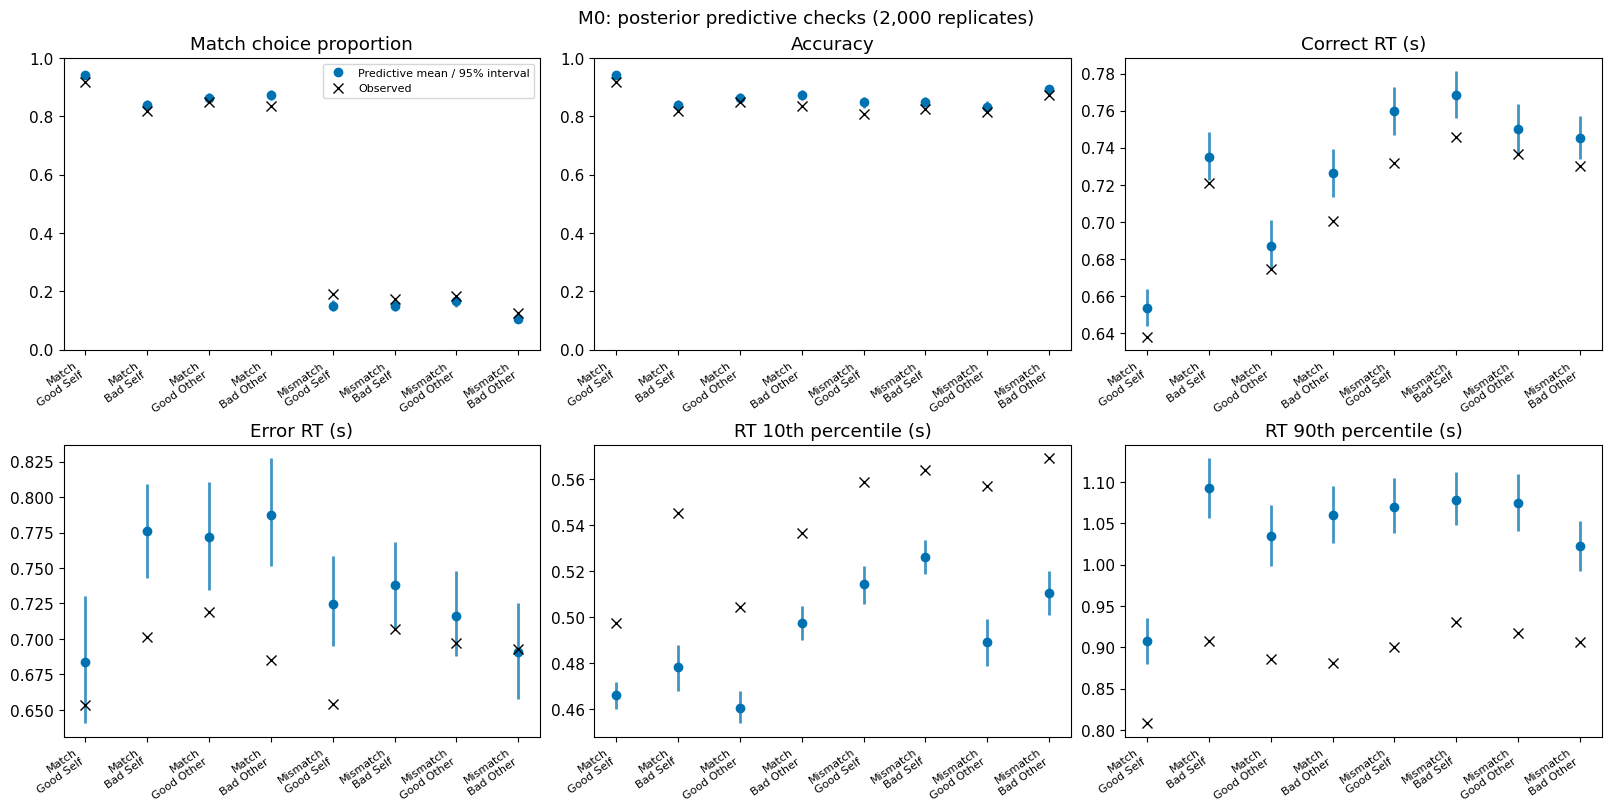

,observed,predicted,bias,mse,outside_95,conditions
metric,,,,,,
Match choice proportion,0.5128,0.5116,-0.0012,0.0007,5,8
Accuracy,0.8432,0.8674,+0.0242,0.0007,5,8
Correct RT (s),0.7099,0.7283,+0.0184,0.0004,8,8
Error RT (s),0.6889,0.7362,+0.0474,0.0033,5,8
RT 10th percentile (s),0.5416,0.4928,-0.0488,0.0026,8,8
RT median (s),0.6962,0.6673,-0.0289,0.0009,8,8
RT 90th percentile (s),0.8919,1.0423,+0.1504,0.0234,8,8


In [14]:
# 六项行为指标：点为均值，区间为 95% 后验预测区间。
for name, table in ppc_tables.items():
    metrics = ["p_match", "accuracy", "mean_correct_rt", "mean_error_rt", "rt_q10", "rt_q90"]
    titles = ["Match choice proportion", "Accuracy", "Correct RT (s)",
              "Error RT (s)", "RT 10th percentile (s)", "RT 90th percentile (s)"]
    order = pd.DataFrame([(stim, val, identity) for stim in (1, 0)
                         for identity in ("Self", "Other") for val in ("Good", "Bad")],
                        columns=["stim", "val", "id"])
    labels = [f"{'Match' if r.stim else 'Mismatch'}\n{r.val} {r.id}" for r in order.itertuples()]
    color = {"M0": "#0072B2", "M1": "#E69F00"}[name]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout="constrained")
    for ax, metric, title in zip(axes.flat, metrics, titles):
        part = order.merge(table.loc[table.metric.eq(metric)], on=["stim", "val", "id"], validate="one_to_one")
        x = np.arange(len(part))
        ax.vlines(x, part.predicted_lower, part.predicted_upper, color=color, linewidth=2, alpha=.75)
        ax.plot(x, part.predicted_mean, "o", color=color, label="Predictive mean / 95% interval")
        ax.plot(x, part.observed, "x", color="black", markersize=7, label="Observed")
        ax.set_xticks(x, labels, rotation=35, ha="right", fontsize=8)
        ax.set_title(title)
        if metric in ("p_match", "accuracy"): ax.set_ylim(0, 1)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{name}: posterior predictive checks ({stamps[name]['n_chains'] * N_PPC_PER_CHAIN:,} replicates)")
    if RUN_POSTPROCESS: fig.savefig(OUT / f"{name}_{REPORT_DATE}_ppc.png", dpi=150, bbox_inches="tight")
    plt.show()
    # 各指标等权汇总八个条件，保留秒与比例各自的尺度。
    overview = table.assign(error=table.predicted_mean-table.observed, squared_error=(table.predicted_mean-table.observed)**2).groupby("metric").agg(
        observed=("observed", "mean"), predicted=("predicted_mean", "mean"),
        bias=("error", "mean"), mse=("squared_error", "mean"),
        outside_95=("outside_interval", "sum"), conditions=("metric", "size"))
    metric_labels = {"p_match": "Match choice proportion", "accuracy": "Accuracy",
        "mean_correct_rt": "Correct RT (s)", "mean_error_rt": "Error RT (s)",
        "rt_q10": "RT 10th percentile (s)", "rt_q50": "RT median (s)",
        "rt_q90": "RT 90th percentile (s)"}
    display(overview.loc[list(metric_labels)].rename(index=metric_labels)
        .style.format({"observed": "{:.4f}", "predicted": "{:.4f}", "bias": "{:+.4f}",
                       "mse": "{:.4f}", "outside_95": "{:.0f}", "conditions": "{:.0f}"}))
if not ppc_tables: print("未找到与完整后验对应的 PPC。")


M0 的八条件 RT 第 90 百分位平均预测误差为 +0.150 秒，正确率平均误差为 +2.42 个百分点。这是各条件统计量的等权平均。PPC 仍存在失配，因此相对排名不代表模型已充分解释行为。

### 反应时分布

沿用已保存 PPC 的前 100 组后验位置与随机种子，生成分布图；原有统计量检验仍使用 2,000 组复制数据。RT 按 25 ms 分箱，实线为预测均值，阴影为逐箱 95% 后验预测区间，黑色虚线为观测密度。

预测分布未截断。图中展示 0–2 秒，超过 2 秒的预测概率另作标注，不因绘图范围重新归一化；观测的 RT 下限选择及 Deadline 限制仍然保留。

In [15]:
# 重放已有 PPC 的前 100 个抽样记录，仅保存分箱密度，不保存完整试次复制。
from common.evaluation_utils import load_chains
from common.baseline_v import trial_parameters
from common.simulation_utils import simulate_from_parameters

density_data = None
if MODEL in posteriors and MODEL in ppc_tables:
    directory = FIT_ROOT / MODEL / ("ppc_" + stamps[MODEL]["posterior_hash"][:16])
    density_path = directory / f"rt_density_{N_PPC_DENSITY}.npz"
    if RUN_PPC_DENSITY and not density_path.exists():
        manifest = json.loads((directory / "ppc_manifest.json").read_text())
        selections = manifest["selections"][:N_PPC_DENSITY]
        assert len(selections) == N_PPC_DENSITY and manifest["dataset_hash"] == dataset_hash(train)
        frames, configs = load_chains(FIT_ROOT / MODEL)
        subject_ids = np.sort(train.subj_idx.unique())
        selected_subjects = subject_ids[[0, len(subject_ids)//2, -1]]
        cells = [(stim, identity, val) for stim in (1, 0)
                 for identity in ("Self", "Other") for val in ("Good", "Bad")]
        masks = [(train.stim.eq(stim) & train.id.eq(identity) & train.val.eq(val)).to_numpy()
                 for stim, identity, val in cells]
        masks += [train.subj_idx.eq(subject).to_numpy() for subject in selected_subjects]
        bins = np.linspace(0, 3, 121)  # 25 ms 分箱；图外尾部单独记录，不重新归一化。
        def bin_rt(frame):
            values = [frame.rt.to_numpy()[mask] for mask in masks]
            densities = np.array([np.histogram(x, bins)[0] / (len(x)*np.diff(bins)) for x in values])
            tails = np.array([[np.mean(x > 2), np.mean(x > bins[-1])] for x in values])
            assert np.isfinite(frame.rt).all() and frame.rt.ge(0).all()
            assert np.allclose((densities*np.diff(bins)).sum(axis=1) + tails[:, 1], 1)
            return densities, tails
        observed_density, observed_tail = bin_rt(train)
        density_draws, tail_draws = [], []
        for selection in selections:
            draw = frames[selection["chain"]].iloc[selection["draw"]]
            simulated = simulate_from_parameters(train, trial_parameters(draw, train, MODEL),
                                                  seed=selection["seed"])
            assert np.array_equal(simulated.event_id.to_numpy(), train.event_id.to_numpy())
            density, tail = bin_rt(simulated)
            density_draws.append(density); tail_draws.append(tail)
        np.savez_compressed(density_path, bins=bins, observed=observed_density,
            predicted=np.stack(density_draws), observed_tail=observed_tail,
            predicted_tail=np.stack(tail_draws), subjects=selected_subjects,
            counts=np.array([mask.sum() for mask in masks]),
            data_hash=dataset_hash(train), posterior_hash=stamps[MODEL]["posterior_hash"],
            selection_ids=np.array([s["replicate"] for s in selections]))
        del frames, simulated, density_draws, tail_draws
    if density_path.exists():
        with np.load(density_path, allow_pickle=False) as saved:
            density_data = {key: saved[key] for key in saved.files}
        assert str(density_data["data_hash"]) == dataset_hash(train)
        assert str(density_data["posterior_hash"]) == stamps[MODEL]["posterior_hash"]
        assert len(density_data["predicted"]) == N_PPC_DENSITY
    else:
        print("RT 分布预测尚未生成。")


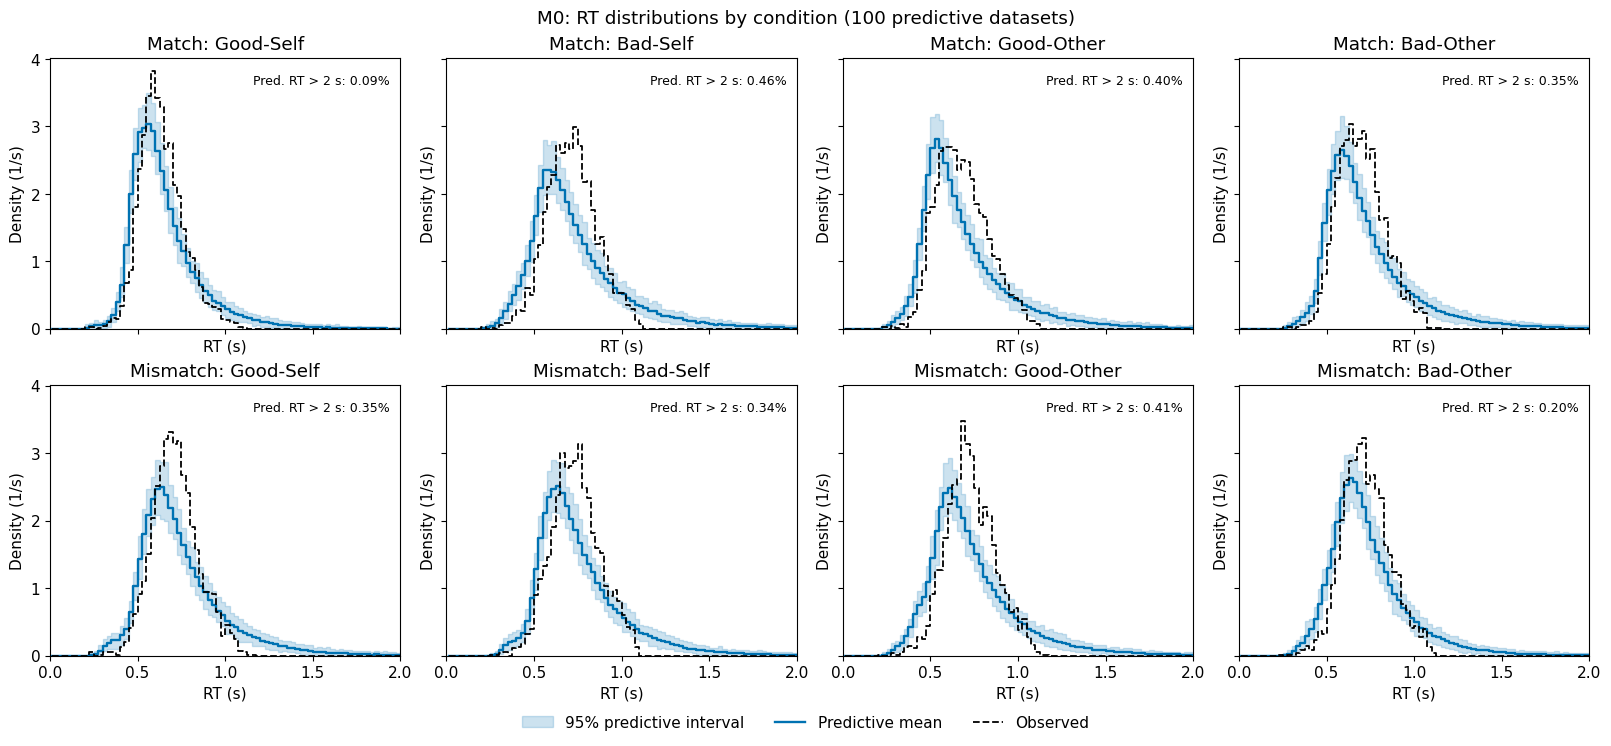

In [16]:
# 每个条件使用全部试次作分母，绘图区间外的概率保留在尾部标注中。
if density_data is not None:
    centers = (density_data["bins"][:-1] + density_data["bins"][1:]) / 2
    prediction = density_data["predicted"]
    lower, upper = np.quantile(prediction, [.025, .975], axis=0)
    mean = prediction.mean(axis=0)
    color = {"M0": "#0072B2", "M1": "#E69F00"}[MODEL]
    def plot_rt_density(ax, position, title):
        ax.fill_between(centers, lower[position], upper[position], color=color,
                        alpha=.2, step="mid", label="95% predictive interval")
        ax.step(centers, mean[position], where="mid", color=color, lw=1.7,
                label="Predictive mean")
        ax.step(centers, density_data["observed"][position], where="mid", color="black",
                lw=1.3, linestyle="--", label="Observed")
        tail = density_data["predicted_tail"][:, position, 0].mean()
        ax.text(.97, .94, f"Pred. RT > 2 s: {tail:.2%}", ha="right", va="top",
                transform=ax.transAxes, fontsize=9)
        ax.set(title=title, xlabel="RT (s)", ylabel="Density (1/s)", xlim=(0, 2))
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True, layout="constrained")
    for position, ax in enumerate(axes.flat):
        plot_rt_density(ax, position, condition_labels[position])
    axes[0, 0].set_ylim(0, 1.05*max(upper[:8].max(), density_data["observed"][:8].max()))
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(.5, -.055), ncol=3, frameon=False)
    fig.suptitle(f"{MODEL}: RT distributions by condition ({N_PPC_DENSITY} predictive datasets)")
    plt.show()


### 个体预测

按被试编号排序，选取首位、中位与末位三名被试；选择规则与拟合质量无关。每幅图合并该被试八条件试次，作为总体分布检查的个体补充。

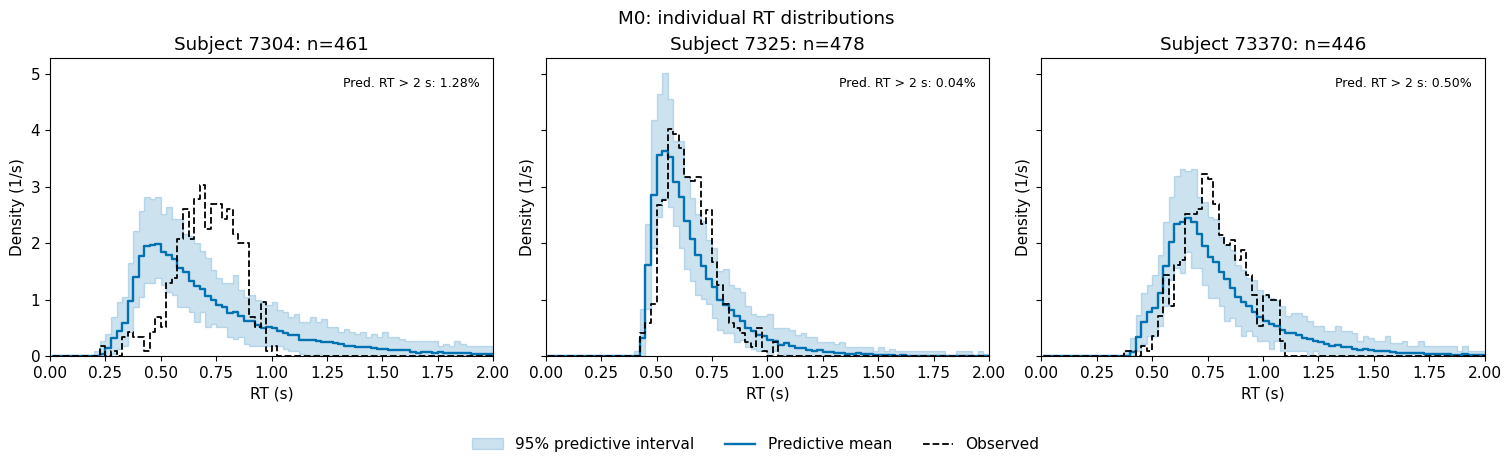

In [17]:
# 被试按编号首位、中位、末位固定选取；每图合并该被试八条件试次。
if density_data is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True, layout="constrained")
    for offset, (ax, subject) in enumerate(zip(axes, density_data["subjects"])):
        position = 8 + offset
        plot_rt_density(ax, position, f"Subject {subject}: n={density_data['counts'][position]}")
    axes[0].set_ylim(0, 1.05*max(upper[8:].max(), density_data["observed"][8:].max()))
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(.5, -.15), ncol=3, frameon=False)
    fig.suptitle(f"{MODEL}: individual RT distributions")
    plt.show()


## 5. Statistical Inference

目标对比在同一 chain/draw 内配对计算，报告后验均值、95% HDI 与 $P(\Delta>0)$。漂移率对比分别在 Match 与 Mismatch 条件计算。

表中正向概率用于有符号参数和条件对比；标准差及正值约束参数不作方向检验。接近 1 的后验比例不表示逻辑上的确定性。

In [18]:
# 汇总目标参数的均值、95% HDI 和正向概率。
for name, trace in posteriors.items():
    variables = [v for v in trace.posterior.data_vars if
                 v.startswith("delta_v_") or v in ('a', 'v_std', 't_std', 'z_trans')]
    rows=[]
    for variable in variables:
        x=trace.posterior[variable].values.reshape(-1)
        lo, hi = az.hdi(x, hdi_prob=.95)
        rows.append(dict(parameter=variable,mean=x.mean(),hdi_lower95=lo,hdi_upper95=hi,p_gt_zero=float(np.mean(x > 0)),
                         posterior_reliable=diagnostic_pass.get(name,False)))
    print(name, "参数与条件对比")
    summary = pd.DataFrame(rows)
    # 展示层标明条件与尺度；保存文件仍使用原字段和完整精度。
    labels = {"a": "a: 群体均值", "v_std": "v: 被试间 SD",
              "t_std": "t0: 被试间 SD (s)", "z_trans": "logit(z): 群体均值",
              "mu_beta_z": "beta_z: 群体均值", "sigma_beta_z": "beta_z: 被试间 SD",
              "mean_delta_z": "平均起点差: Good-self − Bad-self"}
    for direction in ("match", "mismatch"):
        labels["delta_v_" + direction] = direction.title() + ": Good-self − Bad-self"
        for suffix, contrast in {"GoodSelf_GoodOther": "Good-self − Good-other",
                                 "GoodOther_BadOther": "Good-other − Bad-other",
                                 "BadSelf_BadOther": "Bad-self − Bad-other"}.items():
            labels["delta_v_" + direction + "_" + suffix] = direction.title() + ": " + contrast
    result_view = summary[["parameter", "mean", "hdi_lower95", "hdi_upper95", "p_gt_zero"]].copy()
    positive_only = result_view.parameter.isin(["a", "v_std", "t_std", "sigma_beta_z"])
    result_view.loc[positive_only, "p_gt_zero"] = np.nan
    result_view["parameter"] = result_view.parameter.map(lambda value: labels.get(value, value))
    display(result_view.rename(columns={"parameter": "参数 / 漂移对比", "mean": "均值",
        "hdi_lower95": "95% HDI 下限", "hdi_upper95": "95% HDI 上限", "p_gt_zero": "P(>0)"})
        .style.hide(axis="index").format({"均值": "{:.3f}", "95% HDI 下限": "{:.3f}",
            "95% HDI 上限": "{:.3f}", "P(>0)": "{:.4f}"}, na_rep="—"))
    if RUN_POSTPROCESS:
        FIT_ROOT.mkdir(parents=True, exist_ok=True)
        summary.to_csv(FIT_ROOT / (name + "_posterior_summary.csv"), index=False)
if not posteriors: print("参数推断待完成：缺少当前后验。")

M0 参数与条件对比


参数 / 漂移对比,均值,95% HDI 下限,95% HDI 上限,P(>0)
a: 群体均值,1.291,1.253,1.329,—
v: 被试间 SD,0.650,0.590,0.710,—
t0: 被试间 SD (s),0.092,0.085,0.100,—
logit(z): 群体均值,0.185,0.146,0.225,1.0000
Match: Good-self − Bad-self,0.948,0.835,1.067,1.0000
Match: Good-self − Good-other,0.715,0.600,0.833,1.0000
Match: Good-other − Bad-other,-0.038,-0.149,0.078,0.2529
Match: Bad-self − Bad-other,-0.270,-0.384,-0.160,0.0000
Mismatch: Good-self − Bad-self,-0.006,-0.119,0.099,0.4602
Mismatch: Good-self − Good-other,0.096,-0.015,0.201,0.9603


### 条件参数

每个后验样本内对 42 名被试等权平均，再计算均值和 95% HDI，与目标漂移对比使用相同的被试权重。$v$ 为证据成分，Mismatch 试次进入似然时取反。区间展示条件参数的不确定性；条件差异以配对后验对比为依据。

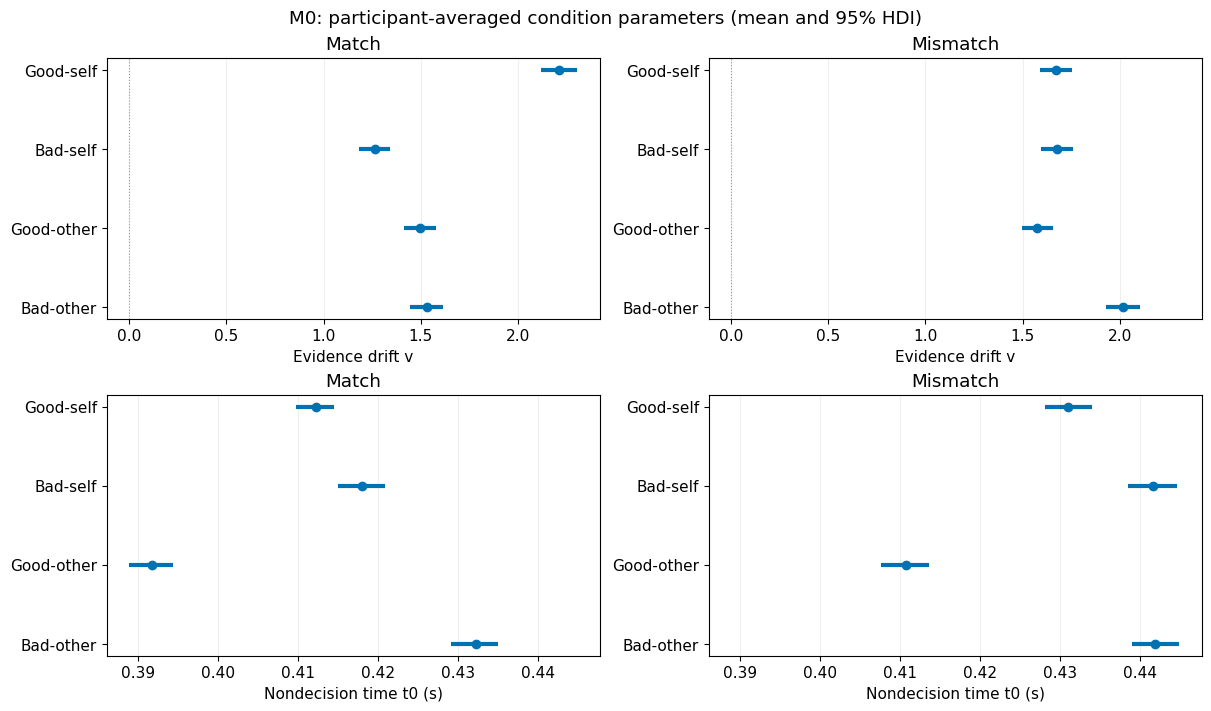

In [19]:
# 每个样本内先对 42 名被试等权平均，再计算条件均值的 95% HDI。
from scipy.special import expit, logit
if MODEL in posteriors:
    posterior = posteriors[MODEL].posterior
    subjects = sorted(train.subj_idx.unique())
    labels = ["Good-self", "Bad-self", "Good-other", "Bad-other"]
    def interval_plot(ax, values, title, xlabel, zero=False):
        for row, samples in enumerate(values):
            samples = np.asarray(samples).reshape(-1)
            lo, hi = az.hdi(samples, hdi_prob=.95)
            ax.hlines(row, lo, hi, color=color, lw=3)
            ax.plot(samples.mean(), row, "o", color=color)
        ax.set(yticks=np.arange(len(values)), yticklabels=labels, title=title, xlabel=xlabel)
        ax.invert_yaxis()
        if zero: ax.axvline(0, color="0.6", lw=.8, linestyle=":")
        ax.grid(axis="x", alpha=.2)
    color = {"M0": "#0072B2", "M1": "#E69F00"}[MODEL]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained", sharex="row")
    for row, (parameter, axis_label) in enumerate((("v", "Evidence drift v"), ("t", "Nondecision time t0 (s)"))):
        for col, match in enumerate(("match", "mismatch")):
            values = [sum(posterior[f"{parameter}_subj({identity}.{match}.{val}).{subject}"]
                          for subject in subjects) / len(subjects)
                      for identity in ("Self", "Other") for val in ("Good", "Bad")]
            interval_plot(axes[row, col], values, match.title(), axis_label, zero=parameter == "v")
    fig.suptitle(f"{MODEL}: participant-averaged condition parameters (mean and 95% HDI)")
    plt.show()


### 结果解释

M0 中，Good-self 相对 Bad-self 的漂移优势出现在 Match 条件，Mismatch 对比的 95% HDI 包含零。相对 DIC 偏向 M1。

分析采用有效响应子集的未截断似然。RT 下限选择与 Deadline 尚未建模，其对上述失配的影响未被量化；机制解释也受有限恢复验证的范围限制。